# 01 — Data Cleaning & Preprocessing Pipeline
## Project: Tech Job Market & Salary Intelligence Platform (India)

**Objective**: This notebook demonstrates an end-to-end data cleaning and engineering workflow that transforms raw, messy tech job postings into standardized, validated datasets and relational Star-Schema dimensional tables.

---
### Workflow Steps:
1. **Data Ingestion & Profiling**: Inspecting initial schema, data types, and missingness.
2. **Deduplication**: Detecting and removing duplicate job postings.
3. **Location Normalization**: Standardizing city variants (e.g., Bangalore -> Bengaluru) across Indian tech hubs.
4. **Experience Parsing**: Extracting numerical minimum/maximum years and creating 4 seniority brackets.
5. **Salary Standardization & Imputation**: Converting all compensation to INR Lakhs per Annum (LPA) and handling missing values with conditional group medians.
6. **Skill Canonicalization**: Normalizing skill strings into consistent casing and categories.
7. **Star-Schema Dimensional Modeling**: Exporting clean tables (`dim_roles`, `dim_companies`, `dim_locations`, `dim_dates`, `dim_skills`, `fact_jobs`, `fact_job_skills`).


In [1]:
# Step 1: Import Core Libraries
import os
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure workspace root is in sys.path
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))

# Set clean visualization style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Step 2: Load Raw Job Market Data
raw_path = "data/raw/raw_jobs_india.csv" if os.path.exists("data/raw/raw_jobs_india.csv") else "../data/raw/raw_jobs_india.csv"
output_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"

df_raw = pd.read_csv(raw_path)
print(f"Total Raw Records: {len(df_raw):,}")
print(f"Total Columns: {len(df_raw.columns)}")
df_raw.head(3)


Total Raw Records: 6,500
Total Columns: 20
Out[2]: 
           job_id  ...     source
0  IND_JOB_000001  ...  Instahyre
1  IND_JOB_000002  ...  Instahyre
2  IND_JOB_000003  ...     Hasjob

[3 rows x 20 columns]


,job_id,job_title,role_category,company,company_tier,location_raw,salary_raw,min_salary_lpa_raw,max_salary_lpa_raw,experience_raw,min_exp_years,max_exp_years,employment_type,industry,education_raw,skills_raw,description_raw,posted_date,job_url,source
0,IND_JOB_000001,Applied Data Scientist,Data Scientist,Wipro,IT_Consulting_Enterprise,Bengaluru / Bangalore,Competitive,NaN,NaN,6 - 9 Yrs,6,9,Full-Time,EdTech & Consumer Internet,"Bachelor's / Master's degree in Statistics, Ma...","Feature Engineering, XGBoost, Machine Learning...",We are seeking a talented Applied Data Scienti...,2026-04-05,https://www.techjobs-india-portal.com/job/000001,Instahyre
1,IND_JOB_000002,Machine Learning Engineer,AI/ML Engineer,Urban Company,Product_Unicorn,Bengaluru,₹ 67.8 LPA,44.79,90.88,7+ Years,7,9,Full-Time,Analytics & Consulting Services,"Bachelor's / Master's degree in Statistics, Ma...","Computer Vision, AWS SageMaker, TensorFlow, Py...",We are seeking a talented Machine Learning Eng...,2026-01-21,https://www.techjobs-india-portal.com/job/000002,Instahyre
2,IND_JOB_000003,SQL & Power BI Developer,Data Analyst,EXL Analytics,Analytics_Specialist,Pune / Pimpri-Chinchwad,₹ 4.2 Lakhs - 7.5 Lakhs,4.24,7.45,0 to 1 Years,0,1,Contract,EdTech & Consumer Internet,"B.Tech / M.Tech / MCA in Computer Science, Dat...","SQL, Business Analysis, Snowflake, Statistics,...",We are seeking a talented SQL & Power BI Devel...,2025-12-18,https://www.techjobs-india-portal.com/job/000003,Hasjob


In [3]:
# Step 3: Check Missing Values in Raw Data
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isnull().sum(),
    "Missing Percentage (%)": (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
missing_summary[missing_summary["Missing Count"] > 0]


Out[3]: 
                    Missing Count  Missing Percentage (%)
salary_raw                    205                    3.15
min_salary_lpa_raw           1070                   16.46
max_salary_lpa_raw           1070                   16.46


,Missing Count,Missing Percentage (%)
salary_raw,205,3.15
min_salary_lpa_raw,1070,16.46
max_salary_lpa_raw,1070,16.46


In [4]:
# Step 4: Run the Standardized Data Cleaner Pipeline
from src.preprocessing.cleaner import TechJobDataCleaner

cleaner = TechJobDataCleaner(raw_data_path=raw_path, output_dir=output_dir)
df_cleaned, schema_tables = cleaner.run_pipeline()

print(f"Cleaned dataset ready: {len(df_cleaned):,} rows")


Reading raw dataset...
[CLEANING LOG] Deduplication: Identified and removed exact duplicates. (Impacted: 0)
[CLEANING LOG] Location Normalization: Normalized all locations to standard Indian tech hubs (Bengaluru, NCR, Hyderabad, Pune, Mumbai, Chennai, Remote). (Impacted: 6500)
[CLEANING LOG] Experience Standardization: Parsed experience ranges and generated standardized 4-tier seniority brackets. (Impacted: 6500)
[CLEANING LOG] Salary Normalization & Imputation: Normalized all salary representations to INR LPA. Imputed 1070 undisclosed postings using conditional median by Role and Experience bracket. (Impacted: 1070)
[CLEANING LOG] Skill Normalization: Mapped raw skill strings to canonical dictionary with consistent casing. (Impacted: 6500)
Saved cleaned flat dataset: data/processed\cleaned_jobs.csv (6500 rows)
Exported Star Schema table: data/processed\dim_roles.csv (4 rows)
Exported Star Schema table: data/processed\dim_companies.csv (480 rows)
Exported Star Schema table: data/proces

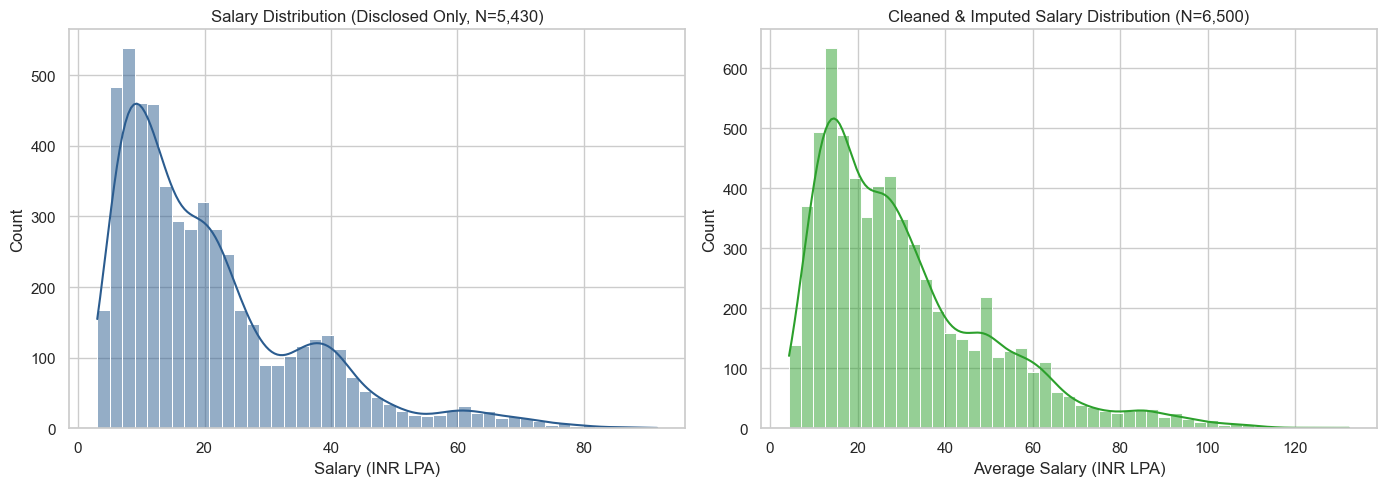

In [5]:
# Step 5: Visualizing Salary Distributions Before and After Imputation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before Imputation (Only Disclosed)
sns.histplot(df_raw["min_salary_lpa_raw"].dropna(), kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Salary Distribution (Disclosed Only, N=5,430)")
axes[0].set_xlabel("Salary (INR LPA)")

# After Normalization & Conditional Imputation
sns.histplot(df_cleaned["avg_salary_lpa"], kde=True, ax=axes[1], color="#2ca02c")
axes[1].set_title("Cleaned & Imputed Salary Distribution (N=6,500)")
axes[1].set_xlabel("Average Salary (INR LPA)")

plt.tight_layout()
plt.show()


In [6]:
# Step 6: Verify Star-Schema Exported Tables
print("Exported Dimensional Tables:")
for table_name, table_df in schema_tables.items():
    print(f"  - {table_name:<18}: {len(table_df):>6,} rows | Columns: {list(table_df.columns)}")


Exported Dimensional Tables:
  - dim_roles         :      4 rows | Columns: ['role_id', 'role_category', 'domain']
  - dim_companies     :    480 rows | Columns: ['company_id', 'company_name', 'company_tier', 'industry']
  - dim_locations     :      9 rows | Columns: ['location_id', 'city', 'state', 'country', 'location_type']
  - dim_dates         :    385 rows | Columns: ['date_id', 'full_date', 'year', 'quarter', 'month', 'month_name', 'year_month', 'day_of_week']
  - dim_skills        :     65 rows | Columns: ['skill_id', 'skill_name', 'skill_category']
  - fact_jobs         :  6,500 rows | Columns: ['job_id', 'job_title', 'role_id', 'company_id', 'location_id', 'date_id', 'min_salary_lpa', 'max_salary_lpa', 'avg_salary_lpa', 'min_salary_inr', 'max_salary_inr', 'avg_salary_inr', 'experience_min', 'experience_max', 'experience_avg', 'experience_bracket', 'employment_type', 'education_requirement', 'is_salary_imputed', 'job_url', 'source']
  - fact_job_skills   : 46,406 rows | Column